In [1]:
# =============================================================================
# CELL 1 -- setup: fixed inc and v_eq, a (lat_centre, ff) grid, quiet template
# =============================================================================
# A GRID TEST of the two band-geometry parameters
#   lat_centre [deg], ff
# with the two kinematic parameters HELD FIXED at the injected truth
#   inc = 75 deg, v_eq = 4000 m/s
# Same forward model, same low resolution and same narrow box as
# Actress_NS_SmallSpace_Test.ipynb, so the grid and the nested-sampling run are
# directly comparable. Nothing here is a precision estimate: the resolution is
# a speed choice, not a physics choice.
#
# Each grid node gets two numbers:
#   chi2  -- against the injected synthetic data (flux excess + profile), the
#            same statistic the sampler maximises
#   CCF   -- Pearson cross-correlation of the node's model profile against the
#            QUIET (no-faculae) profile at the same v_eq and inc. This is a
#            model-manifold diagnostic, NOT a fit statistic: it says how the
#            band deforms the rotational line shape, independent of the data.

import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

import actress as ac   # REFRESH BEFORE USE!

SEED = 20260922

# --- resolution: LOW, for speed. Raises the healpix pixelisation floor. ---
RES_3D = 5      # nside = 2**RES_3D = 32
RES_2D = 200    # projected disc image side, pixels

# --- limb darkening, single line, coefficients held fixed ---
LINE_WAVELENGTH_ANG = 4375.0
hd_ld_table  = np.loadtxt('test_phot.txt')       # cols [wavelength /m, I0, a, b]
fac_ld_table = np.loadtxt('test_fac_200G.txt')
ld_row = int(np.argmin(np.abs(hd_ld_table[:, 0] * 1.0e10 - LINE_WAVELENGTH_ANG)))
PHOT_COEFFS = list(hd_ld_table[ld_row, 1:4])
FAC_COEFFS  = list(fac_ld_table[ld_row, 1:4])

def power2_ld(mu, I0, a, b):
    return I0 * (1.0 - (a * (1.0 - (mu ** b))))

LD_DICT = {'phot': PHOT_COEFFS, 'spot': [1.0e7, 0.3, 0.2],
           'fac': FAC_COEFFS, 'func': power2_ld}

# --- line profile binning ---
N_PROFILE_BINS = 20
PROFILE_HALF_WIDTH_ANG = 0.09
PROFILE_BIN_EDGES = np.linspace(-PROFILE_HALF_WIDTH_ANG, PROFILE_HALF_WIDTH_ANG,
                                N_PROFILE_BINS + 1)
PROFILE_BIN_CENTRES = 0.5 * (PROFILE_BIN_EDGES[:-1] + PROFILE_BIN_EDGES[1:])
PROFILE_BIN_WIDTH_ANG = PROFILE_BIN_EDGES[1] - PROFILE_BIN_EDGES[0]

# one bin, expressed as a Doppler velocity, so CCF lags can be read in m/s.
# c is the same 3e8 m/s hardcoded in simulator.py:525 -- NOT the CODATA value.
# Using CODATA here instead would make the lag axis inconsistent with the shift
# map it is measuring, at the 0.07% level.
C_LIGHT_MS = 3.0e8
BIN_WIDTH_MS = C_LIGHT_MS * PROFILE_BIN_WIDTH_ANG / LINE_WAVELENGTH_ANG

# --- the injected truth: only lat_centre and ff are scanned ---
TRUTH_INC_DEG   = 75.0       # deg, HELD FIXED
TRUTH_V_EQ_MS   = 4000.0     # m/s, HELD FIXED
TRUTH_LAT_DEG   = 25.0       # deg, scanned
TRUTH_FF        = 0.12       # dimensionless, scanned

# --- noise, same as the nested-sampling harness ---
SIGMA_FLUX_REL    = 1.0e-4
SIGMA_PROFILE_REL = 1.0e-3


def band_edges_from_ff(lat_centre_deg, ff):
    """
    Latitude edges [deg] of the band of filling factor ff centred on lat_centre_deg.
    Half-width is arcsin(ff / cos(lat_c)) from f = cos(lat_c) sin(h) (Archimedes).

    Raises if an edge leaves +/-90: hp.query_strip does NOT raise there, it silently
    returns the band reflected about 90 deg with the same area and wrong latitudes.
    The binding condition is ff <= cos^2(lat_c), not ff <= cos(lat_c).
    """
    cos_lat = np.cos(np.radians(lat_centre_deg))
    if ff > cos_lat:
        raise ValueError('ff={:.4f} unreachable at lat={:.2f} (max cos(lat)={:.4f})'
                         .format(ff, lat_centre_deg, cos_lat))
    half_width = np.degrees(np.arcsin(ff / cos_lat))
    lat_low, lat_high = lat_centre_deg - half_width, lat_centre_deg + half_width
    if lat_low < -90.0 or lat_high > 90.0:
        raise ValueError('band {:.2f} to {:.2f} leaves +/-90 for lat={:.2f}, ff={:.4f}; '
                         'limit here is cos^2(lat)={:.4f}'
                         .format(lat_low, lat_high, lat_centre_deg, ff, cos_lat ** 2))
    return lat_low, lat_high


def bin_disc_to_profile(disc, shift_map):
    """
    Collapse a projected disc image onto the wavelength-shift bins.
    Returns the profile normalised to unit sum. Raises if the line has moved out
    of the window: a truncated profile is not the same observable and must not be
    compared to an untruncated one.
    """
    bin_index = np.digitize(shift_map.ravel(), PROFILE_BIN_EDGES) - 1
    in_window = (bin_index >= 0) & (bin_index < N_PROFILE_BINS)
    flat = disc.ravel()
    profile = np.bincount(bin_index[in_window], weights=flat[in_window],
                          minlength=N_PROFILE_BINS)

    total = np.nansum(flat)
    if total - profile.sum() > 1.0e-6 * total:
        raise ValueError('{:.3%} of disc flux falls outside the profile window'
                         .format((total - profile.sum()) / total))

    return profile / profile.sum()


def build_simulator():
    """
    A Simulator with no features, at the test resolution.

    xsize and ld go to the CONSTRUCTOR. Passing them here builds the three
    limb-darkening masks once, at RES_2D. Calling setxsize/setld afterwards instead
    builds them first at the xsize=800 default (simulator.py:70, 117, 128-130),
    throws that away, and rebuilds twice more: ~12x the cost per model call.

    resolution CANNOT go in the constructor: simulator.py:123 validates the argument
    and then hardcodes 2**6, so setresolution is still required or you silently get
    nside=64 regardless of RES_3D.
    """
    sim = ac.Simulator(faculae=[], spots=[], fac_strips=[], spot_strips=[],
                       xsize=RES_2D, ld=LD_DICT)
    sim.setresolution(RES_3D)
    return sim


def forward_model(lat_centre_deg, ff):
    """
    Band model at the FIXED inc and v_eq. Returns (flux_excess, profile).
    Exceptions propagate: a model failure inside the grid is a bug, not a node
    to be quietly skipped.
    """
    lat_low, lat_high = band_edges_from_ff(lat_centre_deg, ff)

    sim = build_simulator()
    sim.addstrip(lower=lat_low, upper=lat_high, feature='fac')

    discs, shift_map = sim.rotate_lc(v_eq=TRUTH_V_EQ_MS, inc=TRUTH_INC_DEG, N=1,
                                     mode='faconly', wavelength=LINE_WAVELENGTH_ANG,
                                     returndisc=True, njobs=1)
    disc = np.asarray(discs)[0]
    return float(np.nanmean(disc)) / QUIET_FLUX, bin_disc_to_profile(disc, shift_map)


# --- the quiet star: template for the cross-correlation, and the flux reference ---
# mode='quiet' changes only makemap (simulator.py:508); the wavelength shift map is
# built from geometry alone (simulator.py:514-531), so the quiet profile is sampled
# on exactly the same Doppler grid as every band model. That is what makes it a
# usable template: it is the rotationally broadened, faculae-free line at the same
# v_eq*sin(inc), not a delta function.
_quiet_sim = build_simulator()
_quiet_discs, _quiet_shift_map = _quiet_sim.rotate_lc(
    v_eq=TRUTH_V_EQ_MS, inc=TRUTH_INC_DEG, N=1, mode='quiet',
    wavelength=LINE_WAVELENGTH_ANG, returndisc=True, njobs=1)
_quiet_disc = np.asarray(_quiet_discs)[0]

QUIET_FLUX = float(np.nanmean(_quiet_disc))
QUIET_PROFILE = bin_disc_to_profile(_quiet_disc, _quiet_shift_map)

# --- synthetic data, injected at the truth ---
rng = np.random.default_rng(SEED)
flux_model, profile_model = forward_model(TRUTH_LAT_DEG, TRUTH_FF)
FLUX_SIGMA = SIGMA_FLUX_REL * flux_model
PROFILE_SIGMA = SIGMA_PROFILE_REL * profile_model.max()
FLUX_DATA = flux_model + rng.normal(0.0, FLUX_SIGMA)
PROFILE_DATA = profile_model + rng.normal(0.0, PROFILE_SIGMA, size=profile_model.shape)

N_DATA = 1 + N_PROFILE_BINS
N_FREE = 2                       # lat_centre and ff; inc and v_eq are pinned
DOF = N_DATA - N_FREE


def chi_squared(lat_centre_deg, ff):
    """Chi-squared over flux excess and profile shape, independent Gaussian errors,
    identical to the log-likelihood in the nested-sampling harness up to -0.5."""
    flux, profile = forward_model(lat_centre_deg, ff)
    chi2 = ((FLUX_DATA - flux) / FLUX_SIGMA) ** 2
    chi2 += np.sum(((PROFILE_DATA - profile) / PROFILE_SIGMA) ** 2)
    return chi2


# --- the grid: the nested-sampling prior box, in the two scanned parameters ---
N_LAT, N_FF = 21, 21
LAT_LO, LAT_HI = 21.0, 29.0      # deg
FF_LO, FF_HI   = 0.100, 0.140
LAT_AXIS = np.linspace(LAT_LO, LAT_HI, N_LAT)
FF_AXIS  = np.linspace(FF_LO, FF_HI, N_FF)

# every node must be geometrically valid, or the grid is probing a region where the
# forward model is not the band the coordinates claim. Worst corner is max lat.
if FF_HI > np.cos(np.radians(LAT_HI)) ** 2:
    raise ValueError('grid corner (lat={}, ff={}) exceeds cos^2(lat)={:.4f}'
                     .format(LAT_HI, FF_HI, np.cos(np.radians(LAT_HI)) ** 2))

_t0 = time.time()
_ = chi_squared(TRUTH_LAT_DEG, TRUTH_FF)
T_MODEL = time.time() - _t0

print('quiet flux             : {:.6f}'.format(QUIET_FLUX))
print('profile bin width      : {:.5f} A  =  {:.1f} m/s at {:.0f} A'
      .format(PROFILE_BIN_WIDTH_ANG, BIN_WIDTH_MS, LINE_WAVELENGTH_ANG))
print('shift map range        : {:+.4f} to {:+.4f} A  ({:.1f} bins half-width)'
      .format(np.nanmin(_quiet_shift_map), np.nanmax(_quiet_shift_map),
              np.nanmax(_quiet_shift_map) / PROFILE_BIN_WIDTH_ANG))
print('data vector            : 1 + {} = {} numbers, {} free parameters, dof = {}'
      .format(N_PROFILE_BINS, N_DATA, N_FREE, DOF))
print('one model call         : {:.4f} s'.format(T_MODEL))
print('grid {} x {} = {} nodes -> {:.1f} s expected'
      .format(N_LAT, N_FF, N_LAT * N_FF, N_LAT * N_FF * T_MODEL))
print('chi2 at truth          : {:.2f}   (dof = {})'.format(
    chi_squared(TRUTH_LAT_DEG, TRUTH_FF), DOF))
print()
print('{:<18} {:>10} {:>10} {:>10} {:>8}'.format(
    'parameter', 'grid lo', 'truth', 'grid hi', 'status'))
print('-' * 60)
print('{:<18} {:>10.4g} {:>10.4g} {:>10.4g} {:>8}'.format(
    'lat_centre [deg]', LAT_LO, TRUTH_LAT_DEG, LAT_HI, 'scanned'))
print('{:<18} {:>10.4g} {:>10.4g} {:>10.4g} {:>8}'.format(
    'ff', FF_LO, TRUTH_FF, FF_HI, 'scanned'))
print('{:<18} {:>10} {:>10.4g} {:>10} {:>8}'.format(
    'inc [deg]', '-', TRUTH_INC_DEG, '-', 'FIXED'))
print('{:<18} {:>10} {:>10.4g} {:>10} {:>8}'.format(
    'v_eq [m/s]', '-', TRUTH_V_EQ_MS, '-', 'FIXED'))

quiet flux             : 15.372176
profile bin width      : 0.00900 A  =  617.1 m/s at 4375 A
shift map range        : -0.0559 to +0.0559 A  (6.2 bins half-width)
data vector            : 1 + 20 = 21 numbers, 2 free parameters, dof = 19
one model call         : 0.0118 s
grid 21 x 21 = 441 nodes -> 5.2 s expected
chi2 at truth          : 30.75   (dof = 19)

parameter             grid lo      truth    grid hi   status
------------------------------------------------------------
lat_centre [deg]           21         25         29  scanned
ff                        0.1       0.12       0.14  scanned
inc [deg]                   -         75          -    FIXED
v_eq [m/s]                  -       4000          -    FIXED


In [2]:
# =============================================================================
# CELL 2 -- cross-correlation machinery, then run the grid
# =============================================================================
# Lag sign convention, stated once and used everywhere below:
#   ccf(lag) correlates profile[i + lag] against template[i], so a profile that
#   is the template shifted REDWARD by s bins peaks at lag = +s. Bin index
#   increases with wavelength (PROFILE_BIN_EDGES runs -0.09 -> +0.09 A), so
#   positive lag = redshift = positive velocity.

CCF_MAX_LAG_BINS = 5      # the line half-width is ~6 bins; beyond ~5 the overlap
                          # is too small for the correlation to mean anything


def cross_correlate(profile, template, max_lag_bins=CCF_MAX_LAG_BINS):
    """
    Pearson correlation of profile against template at integer bin lags.

    The correlation is recomputed on the OVERLAPPING bins at each lag rather than
    normalising once at zero lag. Normalising once would drive the CCF down with
    |lag| purely because fewer bins overlap, which is a windowing artefact and
    would be read as a real loss of correlation.

    Returns (lags, ccf), both length 2*max_lag_bins + 1.
    """
    n_bins = profile.size
    lags = np.arange(-max_lag_bins, max_lag_bins + 1)
    ccf = np.zeros(lags.size)

    for k, lag in enumerate(lags):
        if lag >= 0:
            shifted = profile[lag:]
            reference = template[:n_bins - lag]
        else:
            shifted = profile[:n_bins + lag]
            reference = template[-lag:]

        shifted_centred = shifted - shifted.mean()
        reference_centred = reference - reference.mean()
        denominator = np.sqrt(np.sum(shifted_centred ** 2)
                              * np.sum(reference_centred ** 2))
        if denominator == 0.0:
            raise ValueError('zero variance at lag {}: one of the profiles is flat '
                             'over the overlap, correlation is undefined'.format(lag))
        ccf[k] = np.sum(shifted_centred * reference_centred) / denominator

    return lags, ccf


def ccf_peak(lags, ccf):
    """
    Sub-bin peak of a sampled CCF by 3-point parabolic interpolation about the
    discrete maximum. Returns (peak_lag_bins, peak_height).

    Raises if the maximum sits on the edge of the lag window (the peak is not
    bracketed, so the interpolation would extrapolate) or if the local curvature
    is not negative (not a maximum). Either means the answer is meaningless, so
    it is not returned.
    """
    k = int(np.argmax(ccf))
    if k == 0 or k == ccf.size - 1:
        raise ValueError('CCF maximum at lag {} is on the edge of the +/-{} bin '
                         'window; widen CCF_MAX_LAG_BINS'
                         .format(lags[k], lags[-1]))

    y_minus, y_zero, y_plus = ccf[k - 1], ccf[k], ccf[k + 1]
    curvature = y_minus - 2.0 * y_zero + y_plus
    if curvature >= 0.0:
        raise ValueError('CCF is not concave at its maximum (curvature {:+.3e}); '
                         'the peak is not resolved'.format(curvature))

    sub_bin_offset = 0.5 * (y_minus - y_plus) / curvature
    slope = 0.5 * (y_plus - y_minus)
    peak_height = y_zero - 0.25 * slope ** 2 / (0.5 * curvature)
    return float(lags[k] + sub_bin_offset), float(peak_height)


def ccf_against_quiet(profile):
    """(peak lag [m/s], peak height) of profile cross-correlated with the quiet line."""
    lags, ccf = cross_correlate(profile, QUIET_PROFILE)
    peak_lag_bins, peak_height = ccf_peak(lags, ccf)
    return peak_lag_bins * BIN_WIDTH_MS, peak_height


# --- run the grid -----------------------------------------------------------
# Row index is ff, column index is lat_centre, so imshow/pcolormesh put lat on x.
chi2_grid       = np.full((N_FF, N_LAT), np.nan)
ccf_peak_grid   = np.full((N_FF, N_LAT), np.nan)
ccf_lag_grid    = np.full((N_FF, N_LAT), np.nan)   # m/s
flux_excess_grid = np.full((N_FF, N_LAT), np.nan)

t0 = time.time()
for i_ff, ff_value in enumerate(FF_AXIS):
    for i_lat, lat_value in enumerate(LAT_AXIS):
        flux, profile = forward_model(lat_value, ff_value)

        chi2 = ((FLUX_DATA - flux) / FLUX_SIGMA) ** 2
        chi2 += np.sum(((PROFILE_DATA - profile) / PROFILE_SIGMA) ** 2)

        peak_lag_ms, peak_height = ccf_against_quiet(profile)

        chi2_grid[i_ff, i_lat]        = chi2
        ccf_peak_grid[i_ff, i_lat]    = peak_height
        ccf_lag_grid[i_ff, i_lat]     = peak_lag_ms
        flux_excess_grid[i_ff, i_lat] = flux

    print('  ff = {:.4f} done ({}/{}), {:.1f} s elapsed'
          .format(ff_value, i_ff + 1, N_FF, time.time() - t0))

t_grid = time.time() - t0

# every node must have been filled: a silent NaN here would sit in the chi2 map
# and be read as a region of the parameter space rather than as a failure
if not np.all(np.isfinite(chi2_grid)):
    raise ValueError('{} of {} grid nodes are not finite'
                     .format(int(np.sum(~np.isfinite(chi2_grid))), chi2_grid.size))

# the data, put through the same cross-correlation, so the grid has something to
# be compared against
DATA_LAG_MS, DATA_CCF_PEAK = ccf_against_quiet(PROFILE_DATA)

print()
print('grid wall time      : {:.1f} s for {} nodes ({:.4f} s each)'
      .format(t_grid, chi2_grid.size, t_grid / chi2_grid.size))
print('chi2 range          : {:.2f} to {:.2f}'.format(chi2_grid.min(), chi2_grid.max()))
print('CCF peak range      : {:.8f} to {:.8f}'
      .format(ccf_peak_grid.min(), ccf_peak_grid.max()))
print('CCF lag range       : {:+.4f} to {:+.4f} m/s  ({:+.2e} to {:+.2e} bins)'
      .format(ccf_lag_grid.min(), ccf_lag_grid.max(),
              ccf_lag_grid.min() / BIN_WIDTH_MS, ccf_lag_grid.max() / BIN_WIDTH_MS))
print('data vs quiet       : lag {:+.4f} m/s, peak {:.8f}'
      .format(DATA_LAG_MS, DATA_CCF_PEAK))

  ff = 0.1000 done (1/21), 0.3 s elapsed


  ff = 0.1020 done (2/21), 0.5 s elapsed


  ff = 0.1040 done (3/21), 0.8 s elapsed


  ff = 0.1060 done (4/21), 1.0 s elapsed


  ff = 0.1080 done (5/21), 1.3 s elapsed


...

  ff = 0.1320 done (17/21), 4.4 s elapsed


  ff = 0.1340 done (18/21), 4.6 s elapsed


  ff = 0.1360 done (19/21), 4.8 s elapsed


  ff = 0.1380 done (20/21), 5.1 s elapsed


  ff = 0.1400 done (21/21), 5.3 s elapsed

grid wall time      : 5.3 s for 441 nodes (0.0121 s each)
chi2 range          : 26.06 to 648.87
CCF peak range      : 0.99998017 to 0.99999299
CCF lag range       : +0.0056 to +0.0369 m/s  (+9.06e-06 to +5.98e-05 bins)
data vs quiet       : lag +1.5925 m/s, peak 0.99998639


*** minimum sits on the grid boundary in lat_centre: the box is cutting the fit off, widen it ***
                          lat [deg]           ff         chi2
--------------------------------------------------------------
injected truth              25.0000      0.12000       30.755
grid argmin                 21.0000      0.10800       26.055
Nelder-Mead refined         21.0000      0.10800       26.055
refined - truth             -4.0000     -0.01200            -

grid spacing           : 0.4000 deg in lat, 0.00200 in ff
chi2_min / dof         : 26.055 / 19 = 1.371
model calls in refine  : 29

profiled Delta chi2 = 1 extents (grid-quantised):
  lat_centre [deg]   21 to 22.6
  ff                 0.106 to 0.124


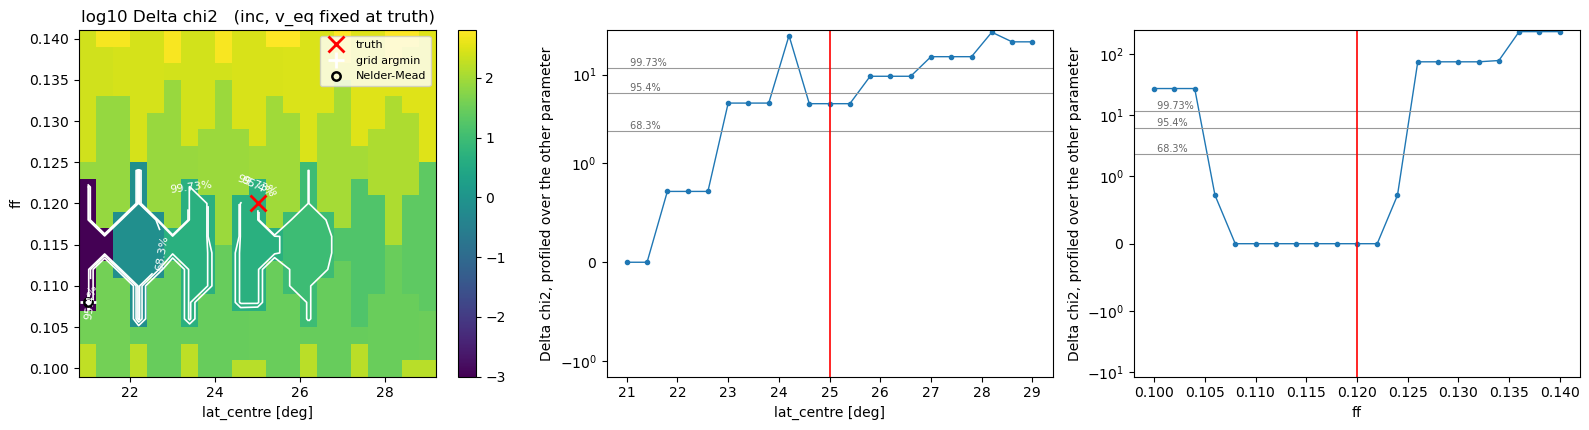

In [3]:
# =============================================================================
# CELL 3 -- chi-squared map and minimisation
# =============================================================================
# Confidence levels are the joint TWO-parameter ones, because both lat_centre and
# ff are free here. Delta chi2 = 2.30, 6.17, 11.83 for 68.3 / 95.4 / 99.73 per cent
# (Press et al., Numerical Recipes 3rd ed., Table 15.6.1, after Avni 1976 ApJ 210 642).
# They assume the Gaussian errors declared in CELL 1 and a locally quadratic chi2;
# neither is checked here, so read them as a scale, not as calibrated intervals.
DELTA_CHI2_LEVELS = [2.30, 6.17, 11.83]
LEVEL_LABELS = ['68.3%', '95.4%', '99.73%']

i_ff_min, i_lat_min = np.unravel_index(np.argmin(chi2_grid), chi2_grid.shape)
lat_grid_min = LAT_AXIS[i_lat_min]
ff_grid_min = FF_AXIS[i_ff_min]
chi2_grid_min = chi2_grid[i_ff_min, i_lat_min]

# refine off the grid node. Nelder-Mead because the forward model is piecewise
# constant at the healpix pixel scale (addstrip snaps band edges to whole pixels),
# so finite-difference gradients are dominated by the pixelisation step and a
# gradient method would stall on it.
refine = minimize(lambda p: chi_squared(p[0], p[1]),
                  x0=np.array([lat_grid_min, ff_grid_min]),
                  method='Nelder-Mead',
                  bounds=[(LAT_LO, LAT_HI), (FF_LO, FF_HI)],
                  options={'xatol': 1.0e-4, 'fatol': 1.0e-4, 'maxiter': 2000})

if not refine.success:
    print('*** Nelder-Mead did NOT converge: {} ***'.format(refine.message))
lat_fit, ff_fit = refine.x
chi2_fit = float(refine.fun)

on_edge = [name for name, value, lo, hi in
           [('lat_centre', lat_fit, LAT_LO, LAT_HI), ('ff', ff_fit, FF_LO, FF_HI)]
           if min(value - lo, hi - value) < 1.0e-6 * (hi - lo)]
if on_edge:
    print('*** minimum sits on the grid boundary in {}: the box is cutting the '
          'fit off, widen it ***'.format(', '.join(on_edge)))

delta_chi2 = chi2_grid - chi2_fit

print('{:<22} {:>12} {:>12} {:>12}'.format('', 'lat [deg]', 'ff', 'chi2'))
print('-' * 62)
print('{:<22} {:>12.4f} {:>12.5f} {:>12.3f}'.format(
    'injected truth', TRUTH_LAT_DEG, TRUTH_FF, chi_squared(TRUTH_LAT_DEG, TRUTH_FF)))
print('{:<22} {:>12.4f} {:>12.5f} {:>12.3f}'.format(
    'grid argmin', lat_grid_min, ff_grid_min, chi2_grid_min))
print('{:<22} {:>12.4f} {:>12.5f} {:>12.3f}'.format(
    'Nelder-Mead refined', lat_fit, ff_fit, chi2_fit))
print('{:<22} {:>12.4f} {:>12.5f} {:>12}'.format(
    'refined - truth', lat_fit - TRUTH_LAT_DEG, ff_fit - TRUTH_FF, '-'))
print()
print('grid spacing           : {:.4f} deg in lat, {:.5f} in ff'
      .format(LAT_AXIS[1] - LAT_AXIS[0], FF_AXIS[1] - FF_AXIS[0]))
print('chi2_min / dof         : {:.3f} / {} = {:.3f}'.format(chi2_fit, DOF, chi2_fit / DOF))
print('model calls in refine  : {}'.format(refine.nfev))

# single-parameter 1-sigma widths, read off the profiled (minimised-over-the-other)
# chi2 at Delta chi2 = 1. Profiling over a 21-node axis quantises these at the grid
# spacing, so they are indicative only.
print()
print('profiled Delta chi2 = 1 extents (grid-quantised):')
for axis_name, axis_values, profiled in [
        ('lat_centre [deg]', LAT_AXIS, delta_chi2.min(axis=0)),
        ('ff', FF_AXIS, delta_chi2.min(axis=1))]:
    within = axis_values[profiled <= 1.0]
    if within.size == 0:
        print('  {:<18} no node within Delta chi2 = 1 (minimum falls between nodes)'
              .format(axis_name))
    elif within.size == axis_values.size:
        print('  {:<18} the WHOLE axis is within Delta chi2 = 1: UNCONSTRAINED here'
              .format(axis_name))
    else:
        print('  {:<18} {:.4g} to {:.4g}'.format(axis_name, within.min(), within.max()))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

mesh = axes[0].pcolormesh(LAT_AXIS, FF_AXIS, np.log10(delta_chi2 + 1.0e-3),
                          shading='nearest', cmap='viridis')
contours = axes[0].contour(LAT_AXIS, FF_AXIS, delta_chi2, levels=DELTA_CHI2_LEVELS,
                           colors='w', linewidths=1.2)
axes[0].clabel(contours, fmt=dict(zip(DELTA_CHI2_LEVELS, LEVEL_LABELS)), fontsize=8)
axes[0].plot(TRUTH_LAT_DEG, TRUTH_FF, 'rx', ms=11, mew=2.0, label='truth')
axes[0].plot(lat_grid_min, ff_grid_min, 'w+', ms=11, mew=2.0, label='grid argmin')
axes[0].plot(lat_fit, ff_fit, 'ko', ms=6, mfc='none', mew=1.8, label='Nelder-Mead')
axes[0].set_xlabel('lat_centre [deg]')
axes[0].set_ylabel('ff')
axes[0].set_title('log10 Delta chi2   (inc, v_eq fixed at truth)')
axes[0].legend(loc='upper right', fontsize=8)
fig.colorbar(mesh, ax=axes[0])

for ax, axis_name, axis_values, profiled, truth_value in [
        (axes[1], 'lat_centre [deg]', LAT_AXIS, delta_chi2.min(axis=0), TRUTH_LAT_DEG),
        (axes[2], 'ff', FF_AXIS, delta_chi2.min(axis=1), TRUTH_FF)]:
    ax.plot(axis_values, profiled, 'o-', ms=3, lw=1.0)
    for level, label in zip(DELTA_CHI2_LEVELS, LEVEL_LABELS):
        ax.axhline(level, color='0.6', lw=0.8)
        ax.text(axis_values[0], level, ' ' + label, fontsize=7, va='bottom', color='0.4')
    ax.axvline(truth_value, color='r', lw=1.2)
    ax.set_yscale('symlog', linthresh=1.0)
    ax.set_xlabel(axis_name)
    ax.set_ylabel('Delta chi2, profiled over the other parameter')

fig.tight_layout()
plt.show()

pixelisation noise floor, from the QUIET profile alone:
  centroid offset      : +5.147e-05 A = +3.5296 m/s   (should be 0 by symmetry)
  max |P(x) - P(-x)|   : 1.144e-02  of a peak bin of 0.1176
    carried by bin 9 at -0.0045 A, 10.77% of that bin
    *** the quiet line should be symmetric about zero shift and is not, at
        the per-cent level. The orthographic pixel grid at RES_2D = 200 does
        not straddle the sub-observer meridian evenly, so the two central
        bins split their flux unequally. Raise RES_2D or use an odd number
        of profile bins if this matters for what you are measuring. ***

measured CCF lags over the grid:
  |lag| max            : 0.0369 m/s = 5.98e-05 bins
  lag at the truth node: +0.0154 m/s
  consistent with zero at the 1%-of-a-bin level, as axisymmetry requires.

CCF peak height against the quiet line (1 - peak, so bigger = more deformed):
  at truth node        : 1 - 0.9999885468 = 1.145e-05
  data vs quiet        : 1 - 0.9999863908 = 1.3

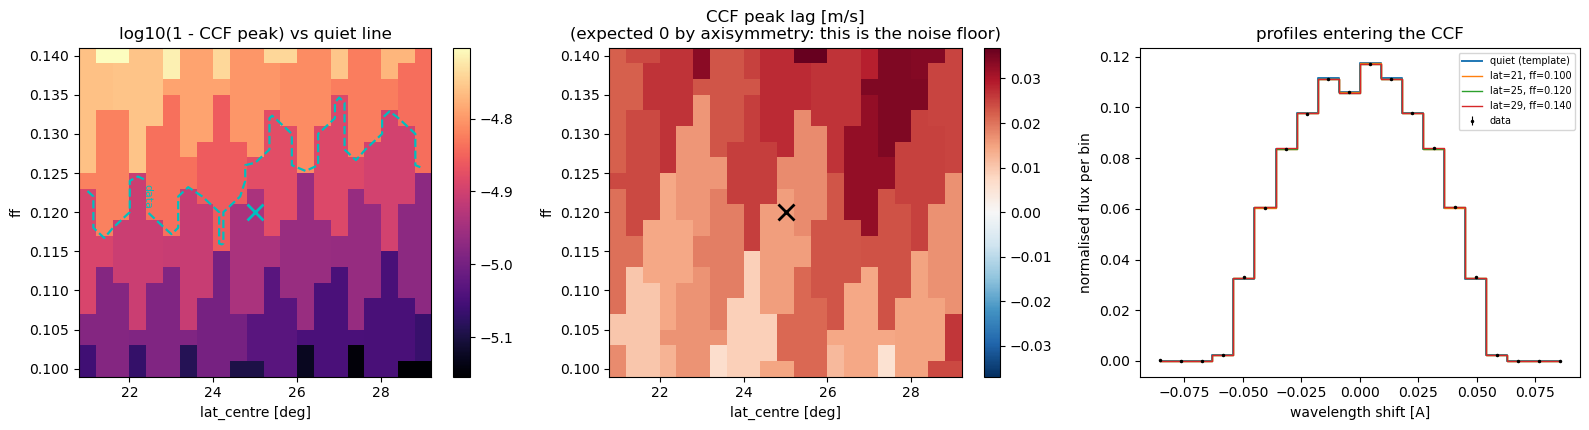


PROVENANCE
  actress                : /rds/general/user/dsy24/home/miniforge3/envs/actress_highres1/lib/python3.9/site-packages/actress-1.0-py3.9.egg/actress/__init__.py (version 1.0)
  seed                   : 20260922
  limb-darkening inputs  : test_phot.txt, test_fac_200G.txt (row 915, 4375.0 A)
  resolution             : RES_3D = 5 (nside 32), RES_2D = 200 px
  nothing was written to disk by this notebook


In [4]:
# =============================================================================
# CELL 4 -- cross-correlation maps, and the axisymmetry check they have to pass
# =============================================================================
# READ THIS BEFORE READING THE LAG MAP.
# addstrip builds a band in LATITUDE, so the feature is axisymmetric in longitude.
# Every facula pixel at line-of-sight velocity +v has a partner at -v on the other
# limb, so the band's contribution to the Doppler distribution is symmetric and the
# expected CCF lag against the quiet line is EXACTLY ZERO for every (lat, ff).
# Whatever the lag map shows is therefore the healpix/orthographic pixelisation
# noise floor, not a physical shift. It is worth having precisely for that reason:
# it bounds how much spurious velocity the discretisation injects.
# The informative map is the CCF PEAK HEIGHT, which measures how much the band
# changes the SHAPE of the rotational profile.

# the quiet profile is not perfectly symmetric either, for the same pixelisation
# reason, so quote its own centroid as the reference scale
quiet_centroid_ang = float(np.sum(QUIET_PROFILE * PROFILE_BIN_CENTRES))
quiet_centroid_ms = C_LIGHT_MS * quiet_centroid_ang / LINE_WAVELENGTH_ANG
quiet_asymmetry = float(np.abs(QUIET_PROFILE - QUIET_PROFILE[::-1]).max())

print('pixelisation noise floor, from the QUIET profile alone:')
print('  centroid offset      : {:+.3e} A = {:+.4f} m/s   (should be 0 by symmetry)'
      .format(quiet_centroid_ang, quiet_centroid_ms))
print('  max |P(x) - P(-x)|   : {:.3e}  of a peak bin of {:.4f}'
      .format(quiet_asymmetry, QUIET_PROFILE.max()))
_worst_bin = int(np.argmax(np.abs(QUIET_PROFILE - QUIET_PROFILE[::-1])))
print('    carried by bin {} at {:+.4f} A, {:.2%} of that bin'
      .format(_worst_bin, PROFILE_BIN_CENTRES[_worst_bin],
              quiet_asymmetry / QUIET_PROFILE[_worst_bin]))
if quiet_asymmetry > 0.01 * QUIET_PROFILE.max():
    print('    *** the quiet line should be symmetric about zero shift and is not, at')
    print('        the per-cent level. The orthographic pixel grid at RES_2D = {} does'.format(RES_2D))
    print('        not straddle the sub-observer meridian evenly, so the two central')
    print('        bins split their flux unequally. Raise RES_2D or use an odd number')
    print('        of profile bins if this matters for what you are measuring. ***')
print()
print('measured CCF lags over the grid:')
print('  |lag| max            : {:.4f} m/s = {:.2e} bins'
      .format(np.abs(ccf_lag_grid).max(), np.abs(ccf_lag_grid).max() / BIN_WIDTH_MS))
print('  lag at the truth node: {:+.4f} m/s'
      .format(ccf_lag_grid[np.argmin(np.abs(FF_AXIS - TRUTH_FF)),
                           np.argmin(np.abs(LAT_AXIS - TRUTH_LAT_DEG))]))
if np.abs(ccf_lag_grid).max() > 0.01 * BIN_WIDTH_MS:
    print('  *** lags exceed 1% of a bin. Either the band is not axisymmetric as')
    print('      assumed, or the pixelisation noise is larger than expected. ***')
else:
    print('  consistent with zero at the 1%-of-a-bin level, as axisymmetry requires.')

print()
print('CCF peak height against the quiet line (1 - peak, so bigger = more deformed):')
print('  at truth node        : 1 - {:.10f} = {:.3e}'
      .format(ccf_peak_grid[np.argmin(np.abs(FF_AXIS - TRUTH_FF)),
                            np.argmin(np.abs(LAT_AXIS - TRUTH_LAT_DEG))],
              1.0 - ccf_peak_grid[np.argmin(np.abs(FF_AXIS - TRUTH_FF)),
                                  np.argmin(np.abs(LAT_AXIS - TRUTH_LAT_DEG))]))
print('  data vs quiet        : 1 - {:.10f} = {:.3e}'
      .format(DATA_CCF_PEAK, 1.0 - DATA_CCF_PEAK))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

# 1 - peak spans orders of magnitude and is what carries the information; plotting
# the peak itself would be a uniform field of 0.9999...
mesh = axes[0].pcolormesh(LAT_AXIS, FF_AXIS, np.log10(1.0 - ccf_peak_grid),
                          shading='nearest', cmap='magma')
level = np.log10(1.0 - DATA_CCF_PEAK)
if np.log10(1.0 - ccf_peak_grid).min() < level < np.log10(1.0 - ccf_peak_grid).max():
    locus = axes[0].contour(LAT_AXIS, FF_AXIS, np.log10(1.0 - ccf_peak_grid),
                            levels=[level], colors='c', linewidths=1.6)
    axes[0].clabel(locus, fmt={level: 'data'}, fontsize=8)
else:
    print()
    print('*** the data CCF peak lies OUTSIDE the range the grid spans, so there is')
    print('    no locus to draw. The grid does not contain a CCF-consistent model. ***')
axes[0].plot(TRUTH_LAT_DEG, TRUTH_FF, 'cx', ms=11, mew=2.0)
axes[0].set_xlabel('lat_centre [deg]')
axes[0].set_ylabel('ff')
axes[0].set_title('log10(1 - CCF peak) vs quiet line')
fig.colorbar(mesh, ax=axes[0])

# symmetric colour scale about zero: the whole point is that this map is noise
lag_scale = np.abs(ccf_lag_grid).max()
mesh = axes[1].pcolormesh(LAT_AXIS, FF_AXIS, ccf_lag_grid, shading='nearest',
                          cmap='RdBu_r', vmin=-lag_scale, vmax=lag_scale)
axes[1].plot(TRUTH_LAT_DEG, TRUTH_FF, 'kx', ms=11, mew=2.0)
axes[1].set_xlabel('lat_centre [deg]')
axes[1].set_ylabel('ff')
axes[1].set_title('CCF peak lag [m/s]\n(expected 0 by axisymmetry: this is the noise floor)')
fig.colorbar(mesh, ax=axes[1])

# the profiles themselves, so the maps above are anchored to something visible
axes[2].step(PROFILE_BIN_CENTRES, QUIET_PROFILE, where='mid', lw=1.4, label='quiet (template)')
for lat_value, ff_value in [(LAT_LO, FF_LO), (TRUTH_LAT_DEG, TRUTH_FF), (LAT_HI, FF_HI)]:
    _, corner_profile = forward_model(lat_value, ff_value)
    axes[2].step(PROFILE_BIN_CENTRES, corner_profile, where='mid', lw=1.0,
                 label='lat={:.0f}, ff={:.3f}'.format(lat_value, ff_value))
axes[2].errorbar(PROFILE_BIN_CENTRES, PROFILE_DATA, yerr=PROFILE_SIGMA, fmt='k.',
                 ms=3, lw=0.8, label='data')
axes[2].set_xlabel('wavelength shift [A]')
axes[2].set_ylabel('normalised flux per bin')
axes[2].set_title('profiles entering the CCF')
axes[2].legend(fontsize=7)

fig.tight_layout()
plt.show()

print()
print('PROVENANCE')
print('  actress                : {} (version {})'.format(ac.__file__, ac.__version__))
print('  seed                   : {}'.format(SEED))
print('  limb-darkening inputs  : test_phot.txt, test_fac_200G.txt (row {}, {:.1f} A)'
      .format(ld_row, hd_ld_table[ld_row, 0] * 1.0e10))
print('  resolution             : RES_3D = {} (nside {}), RES_2D = {} px'
      .format(RES_3D, 2 ** RES_3D, RES_2D))
print('  nothing was written to disk by this notebook')